# 01 — Dataset Profiling

Loads the raw Datafiniti electronics pricing CSV, runs the SignalWatch profiler,
and produces summary statistics and diagnostic figures.

**Outputs**
- `../data/figures/top10_merchants.png`
- `../data/figures/price_distribution.png`
- `../data/figures/pm_pairs_by_bucket.png`
- `../data/processed/dataset_profile.json`

In [1]:
import sys
import os
import json
import warnings

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

warnings.filterwarnings('ignore')

# Make src/ importable from notebooks/
sys.path.insert(0, '..')

from src.data.loader import load_raw
from src.data.profiler import profile, print_report, save_report

# Ensure output directories exist
os.makedirs('../data/figures', exist_ok=True)
os.makedirs('../data/processed', exist_ok=True)

print('Imports OK')

Imports OK


## 1. Load Raw Data

In [2]:
# Resolve CSV path from the DATA_PATH.txt pointer
pointer_file = '../data/raw/DATA_PATH.txt'
try:
    with open(pointer_file, 'r', encoding='utf-8') as fh:
        raw_csv_path = fh.read().strip()
    print(f'Raw data path: {raw_csv_path}')
except FileNotFoundError:
    raise FileNotFoundError(
        f'DATA_PATH.txt not found at {pointer_file}.\n'
        'Create it and write the full path to the CSV on the first line.'
    )

df_raw = load_raw(raw_csv_path)
print(f'Loaded raw DataFrame: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns')

Raw data path: ../DatafinitiElectronicsProductsPricingData.csv


Loaded raw DataFrame: 14,592 rows × 26 columns


## 2. Run Profiler

In [3]:
report = profile(df_raw)
print_report(report)


  SIGNALWATCH — DATASET PROFILING REPORT

Shape: 14,592 rows × 26 columns

Columns:
  id                                   missing=     0  (  0.0%)
  prices.amountMax                     missing=     0  (  0.0%)
  prices.amountMin                     missing=     0  (  0.0%)
  prices.availability                  missing= 1,925  ( 13.2%)
  prices.condition                     missing= 1,403  (  9.6%)
  prices.currency                      missing=     0  (  0.0%)
  prices.dateSeen                      missing=     0  (  0.0%)
  prices.isSale                        missing=     0  (  0.0%)
  prices.merchant                      missing=   772  (  5.3%)
  prices.shipping                      missing= 5,799  ( 39.7%)
  prices.sourceURLs                    missing=     0  (  0.0%)
  asins                                missing=     0  (  0.0%)
  brand                                missing=     0  (  0.0%)
  categories                           missing=     0  (  0.0%)
  dateAdded        

## 3. Shape, Columns & Missing Values

In [4]:
print(f"Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
print("\nColumn names:")
for c in df_raw.columns:
    print(f'  {c}')

Shape: 14,592 rows × 26 columns

Column names:
  id
  prices.amountMax
  prices.amountMin
  prices.availability
  prices.condition
  prices.currency
  prices.dateSeen
  prices.isSale
  prices.merchant
  prices.shipping
  prices.sourceURLs
  asins
  brand
  categories
  dateAdded
  dateUpdated
  ean
  imageURLs
  keys
  manufacturer
  manufacturerNumber
  name
  primaryCategories
  sourceURLs
  upc
  weight


In [5]:
# Missing values table
missing = df_raw.isnull().sum().rename('null_count')
missing_pct = (missing / len(df_raw) * 100).rename('null_pct')
missing_df = pd.concat([missing, missing_pct], axis=1)
missing_df = missing_df[missing_df['null_count'] > 0].sort_values('null_count', ascending=False)
display(missing_df.style.format({'null_pct': '{:.1f}%'}).background_gradient(cmap='Reds', subset=['null_pct']))

,null_count,null_pct
ean,10384,71.2%
manufacturer,6974,47.8%
prices.shipping,5799,39.7%
prices.availability,1925,13.2%
prices.condition,1403,9.6%
prices.merchant,772,5.3%


## 4. Date Range, Price Stats & isSale Distribution

In [6]:
# Date range from report
print('=== Date Range ===')
date_info = report.get('date_range', {})
for k, v in date_info.items():
    print(f'  {k}: {v}')

print('\n=== Price Statistics ===')
price_info = report.get('price_stats', {})
for k, v in price_info.items():
    if isinstance(v, float):
        print(f'  {k}: {v:.4f}')
    else:
        print(f'  {k}: {v}')

print('\n=== isSale Distribution ===')
sale_info = report.get('is_sale', {})
for k, v in sale_info.items():
    print(f'  {k}: {v}')

=== Date Range ===

=== Price Statistics ===

=== isSale Distribution ===


## 5. Explosion Statistics (PM Pairs by Observation Threshold)

In [7]:
print('=== PM Pair Explosion Statistics ===')
explosion = report.get('explosion', report.get('pm_pairs', {}))
if explosion:
    for k, v in explosion.items():
        print(f'  {k}: {v}')
else:
    # Compute inline from report if key not present
    pm_info = report.get('product_merchant_pairs', report.get('pairs', {}))
    print('Explosion key not found in report. Available report keys:')
    print(list(report.keys()))

=== PM Pair Explosion Statistics ===
Explosion key not found in report. Available report keys:
['shape', 'columns', 'missing_values', 'duplicate_rows', 'unique_counts', 'price_statistics', 'is_sale_distribution', 'availability_distribution', 'dateAdded_range', 'dateUpdated_range', 'date_seen_statistics', 'currency_distribution', 'sample_product_names']


## 6. Figure 1 — Top-10 Merchants by Observation Count

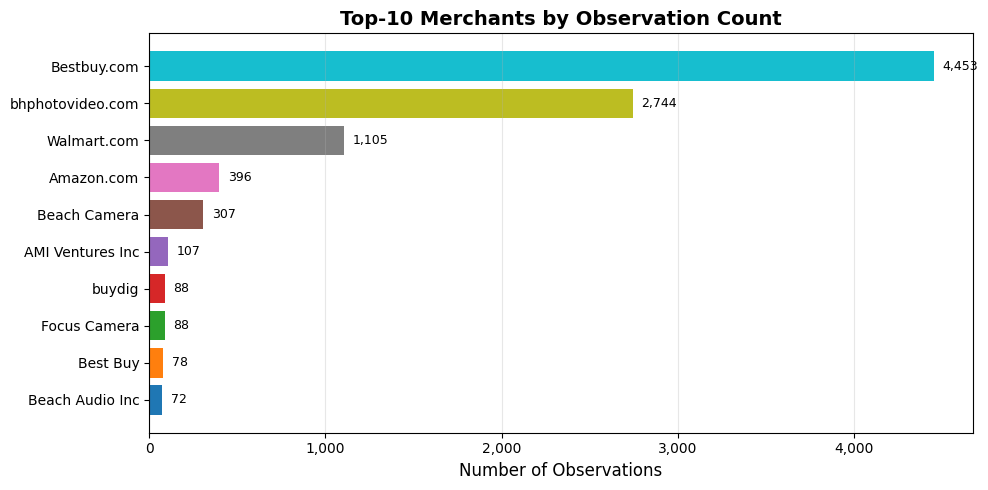

Saved: ../data/figures/top10_merchants.png


In [8]:
merchant_col = 'prices.merchant'
if merchant_col not in df_raw.columns:
    merchant_col = next((c for c in df_raw.columns if 'merchant' in c.lower()), None)

if merchant_col:
    top_merchants = (
        df_raw[merchant_col]
        .dropna()
        .value_counts()
        .head(10)
        .sort_values(ascending=True)
    )

    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.barh(
        top_merchants.index,
        top_merchants.values,
        color=plt.cm.tab10.colors[:10]
    )
    ax.set_xlabel('Number of Observations', fontsize=12)
    ax.set_title('Top-10 Merchants by Observation Count', fontsize=14, fontweight='bold')
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
    for bar, val in zip(bars, top_merchants.values):
        ax.text(bar.get_width() + 50, bar.get_y() + bar.get_height() / 2,
                f'{val:,}', va='center', fontsize=9)
    ax.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.savefig('../data/figures/top10_merchants.png', dpi=100, bbox_inches='tight')
    plt.show()
    print('Saved: ../data/figures/top10_merchants.png')
else:
    print('Merchant column not found in DataFrame.')

## 7. Figure 2 — Price Distribution (Log Scale)

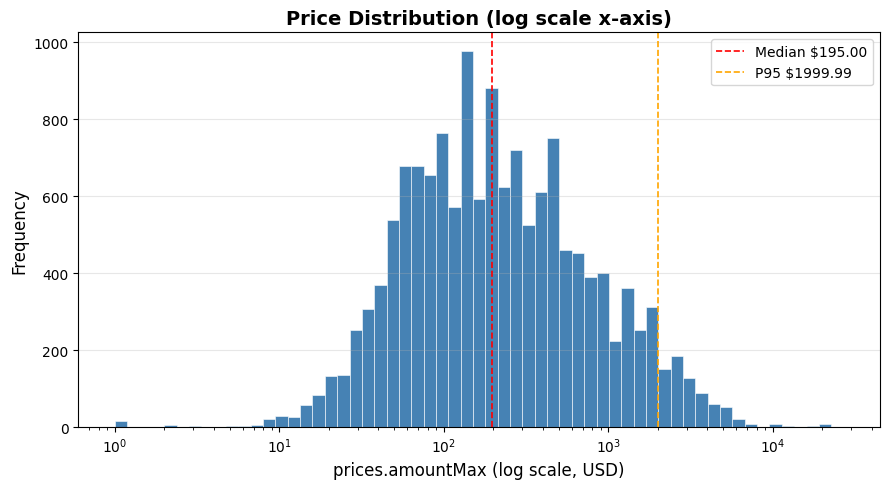

Saved: ../data/figures/price_distribution.png


In [9]:
# Identify a numeric price column
price_col = None
for candidate in ['prices.amountMax', 'prices.amountMin', 'price']:
    if candidate in df_raw.columns:
        price_col = candidate
        break

if price_col:
    prices_numeric = pd.to_numeric(df_raw[price_col], errors='coerce').dropna()
    prices_positive = prices_numeric[prices_numeric > 0]

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.hist(
        prices_positive,
        bins=np.logspace(np.log10(prices_positive.min()), np.log10(prices_positive.max()), 60),
        color='steelblue',
        edgecolor='white',
        linewidth=0.4,
    )
    ax.set_xscale('log')
    ax.set_xlabel(f'{price_col} (log scale, USD)', fontsize=12)
    ax.set_ylabel('Frequency', fontsize=12)
    ax.set_title('Price Distribution (log scale x-axis)', fontsize=14, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    # Annotate p50 and p95
    p50 = prices_positive.median()
    p95 = prices_positive.quantile(0.95)
    ax.axvline(p50, color='red', linestyle='--', linewidth=1.2, label=f'Median ${p50:.2f}')
    ax.axvline(p95, color='orange', linestyle='--', linewidth=1.2, label=f'P95 ${p95:.2f}')
    ax.legend(fontsize=10)
    plt.tight_layout()
    plt.savefig('../data/figures/price_distribution.png', dpi=100, bbox_inches='tight')
    plt.show()
    print('Saved: ../data/figures/price_distribution.png')
else:
    print('No price column found in raw DataFrame.')

## 8. Figure 3 — PM Pairs by Observation Count Bucket

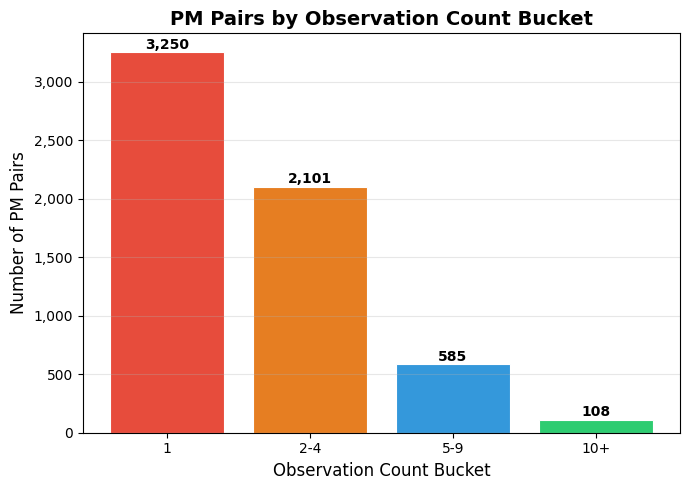

Saved: ../data/figures/pm_pairs_by_bucket.png


In [10]:
# Build per-PM-pair observation counts from raw data
id_col = 'id' if 'id' in df_raw.columns else df_raw.columns[0]
merchant_col_fig = 'prices.merchant'
if merchant_col_fig not in df_raw.columns:
    merchant_col_fig = next((c for c in df_raw.columns if 'merchant' in c.lower()), None)

if merchant_col_fig:
    pm_counts = (
        df_raw
        .dropna(subset=[id_col, merchant_col_fig])
        .groupby([id_col, merchant_col_fig])
        .size()
        .rename('n_obs')
    )

    def obs_bucket(n):
        if n == 1:
            return '1'
        elif n <= 4:
            return '2-4'
        elif n <= 9:
            return '5-9'
        else:
            return '10+'

    bucket_order = ['1', '2-4', '5-9', '10+']
    pm_buckets = pm_counts.apply(obs_bucket).value_counts().reindex(bucket_order, fill_value=0)

    fig, ax = plt.subplots(figsize=(7, 5))
    colors = ['#e74c3c', '#e67e22', '#3498db', '#2ecc71']
    bars = ax.bar(pm_buckets.index, pm_buckets.values, color=colors, edgecolor='white', linewidth=0.8)
    ax.set_xlabel('Observation Count Bucket', fontsize=12)
    ax.set_ylabel('Number of PM Pairs', fontsize=12)
    ax.set_title('PM Pairs by Observation Count Bucket', fontsize=14, fontweight='bold')
    for bar, val in zip(bars, pm_buckets.values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
                f'{val:,}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig('../data/figures/pm_pairs_by_bucket.png', dpi=100, bbox_inches='tight')
    plt.show()
    print('Saved: ../data/figures/pm_pairs_by_bucket.png')
else:
    print('Could not find merchant column for PM-pair bucket chart.')

## 9. Save Profile JSON

In [11]:
output_path = '../data/processed/dataset_profile.json'
save_report(report, output_path)
print(f'Profile JSON saved to: {output_path}')

# Verify it roundtrips
with open(output_path, 'r', encoding='utf-8') as fh:
    loaded = json.load(fh)
print(f'Top-level keys: {list(loaded.keys())}')

Profile JSON saved to: ../data/processed/dataset_profile.json
Top-level keys: ['shape', 'columns', 'missing_values', 'duplicate_rows', 'unique_counts', 'price_statistics', 'is_sale_distribution', 'availability_distribution', 'dateAdded_range', 'dateUpdated_range', 'date_seen_statistics', 'currency_distribution', 'sample_product_names']
